# Churn risk model

**Goal.** Each month, give the customer success team a ranked list of paying accounts most likely to
cancel in the next 60 days, early enough to do something about it.

**Why it's a fair test.** The model is trained on point-in-time *snapshots*. On the first of each month,
every paying account is described using only what was known on that day (usage in the previous 28 and
56 days, plan, seats, tenure, time to renewal), and labelled by whether it cancelled in the following
60 days. Training uses earlier snapshots, testing uses later ones, the same way the model would be
used in practice.

Feature code lives in `analysis/churn_features.py`; the inputs are the warehouse's core tables.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from analysis.churn_features import load_inputs, snapshots, snapshot
from analysis.warehouse import write

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2f6fdb", "#8a8f98"

In [2]:
inputs = load_inputs()
data = snapshots(inputs, pd.date_range("2025-03-01", "2026-08-01", freq="MS"))

NUMERIC = ["mrr_usd", "seats", "plan_tier", "is_annual", "discount_pct", "tenure_months",
           "months_to_renewal", "users_total", "users_added_56d", "active_users_28d", "user_days_28d",
           "sessions_28d", "reports_28d", "user_days_trend", "active_share_of_seats", "days_since_last_active"]
CATEGORICAL = ["segment", "signup_channel"]
FEATURES = NUMERIC + CATEGORICAL
LABEL = "churned_60d"

print(f"{len(data):,} account-month snapshots, {data['account_id'].nunique():,} accounts, "
      f"churn rate {data[LABEL].mean():.1%}")
data.groupby("snapshot_date")[LABEL].agg(accounts="size", churned="sum").T

7,288 account-month snapshots, 890 accounts, churn rate 3.8%


snapshot_date,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
accounts,115,143,183,210,239,272,299,323,355,394,430,457,512,576,618,674,727,761
churned,6,5,5,7,8,10,13,12,13,14,17,16,15,13,22,35,36,30


Only about 4% of snapshots end in churn. With that imbalance, accuracy is meaningless (predicting "nobody
churns" is 96% accurate), so the model is judged on ranking: ROC AUC, precision-recall, and above all
how many churners land in the top of the list.

**Split.** Snapshots from March 2025 to January 2026 train the model; February to August 2026 test it.

In [3]:
train = data[data["snapshot_date"] < "2026-02-01"]
test = data[data["snapshot_date"] >= "2026-02-01"]
print(f"train: {len(train):,} rows, {train[LABEL].sum()} churns | test: {len(test):,} rows, {test[LABEL].sum()} churns")

preprocess = make_column_transformer(
    (StandardScaler(), NUMERIC),
    (OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
)
models = {
    "Logistic regression": make_pipeline(preprocess, LogisticRegression(max_iter=2000)),
    "Gradient boosting": make_pipeline(
        make_column_transformer((OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
                                remainder="passthrough"),
        HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                       l2_regularization=1.0, random_state=0)),
}
scores = {}
for name, model in models.items():
    model.fit(train[FEATURES], train[LABEL])
    scores[name] = model.predict_proba(test[FEATURES])[:, 1]


def top_share(y, p, share):
    k = int(round(len(y) * share))
    top = np.argsort(-p)[:k]
    return y[top].mean(), y[top].sum() / y.sum()


y = test[LABEL].to_numpy()
summary = {}
for name, p in scores.items():
    prec10, rec10 = top_share(y, p, 0.10)
    summary[name] = {"ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p),
                     "Precision in top 10%": prec10, "Churners caught in top 10%": rec10,
                     "Lift in top 10%": prec10 / y.mean()}
summary["Random ranking"] = {"ROC AUC": 0.5, "PR AUC": y.mean(), "Precision in top 10%": y.mean(),
                             "Churners caught in top 10%": 0.10, "Lift in top 10%": 1.0}
pd.DataFrame(summary).T.style.format({"ROC AUC": "{:.3f}", "PR AUC": "{:.3f}", "Precision in top 10%": "{:.1%}",
                                       "Churners caught in top 10%": "{:.0%}", "Lift in top 10%": "{:.1f}x"})

train: 2,963 rows, 110 churns | test: 4,325 rows, 167 churns


,ROC AUC,PR AUC,Precision in top 10%,Churners caught in top 10%,Lift in top 10%
Logistic regression,0.798,0.155,13.4%,35%,3.5x
Gradient boosting,0.800,0.160,15.5%,40%,4.0x
Random ranking,0.500,0.039,3.9%,10%,1.0x


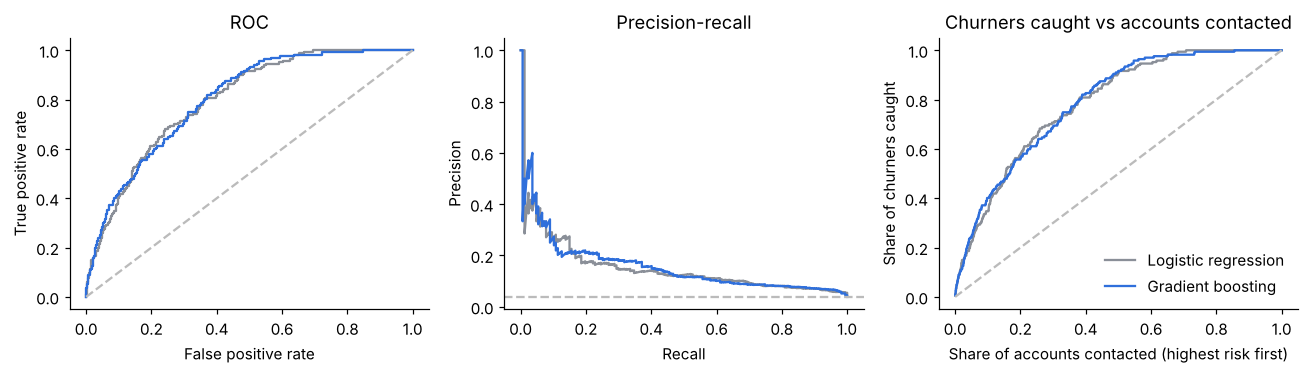

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for (name, p), color in zip(scores.items(), [GREY, BLUE]):
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, color=color, label=name)
    prec, rec, _ = precision_recall_curve(y, p)
    axes[1].plot(rec, prec, color=color, label=name)
    order = np.argsort(-p)
    captured = np.cumsum(y[order]) / y.sum()
    axes[2].plot(np.arange(1, len(y) + 1) / len(y), captured, color=color, label=name)
axes[0].plot([0, 1], [0, 1], ls="--", color="#bbb")
axes[0].set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y.mean(), ls="--", color="#bbb")
axes[1].set(title="Precision-recall", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], ls="--", color="#bbb")
axes[2].set(title="Churners caught vs accounts contacted", xlabel="Share of accounts contacted (highest risk first)",
            ylabel="Share of churners caught")
axes[2].legend(frameon=False, loc="lower right")
plt.tight_layout()

Both models rank far better than chance, and gradient boosting is only slightly ahead of logistic
regression. When a simple, explainable model is nearly as good, that is a reason to keep it in mind:
it is easier to explain to the customer success team and to monitor.

Churn here is genuinely hard to predict: many cancellations come from accounts that looked healthy (a
company closing, a competitor's offer). The aim is a useful list, not certainty.

## Are the probabilities trustworthy?

If the model says 20%, about 20% of those accounts should churn. Calibration matters because the
dashboard shows expected MRR at risk, which is probability times MRR.

Mean predicted 2.9% vs observed 3.9%


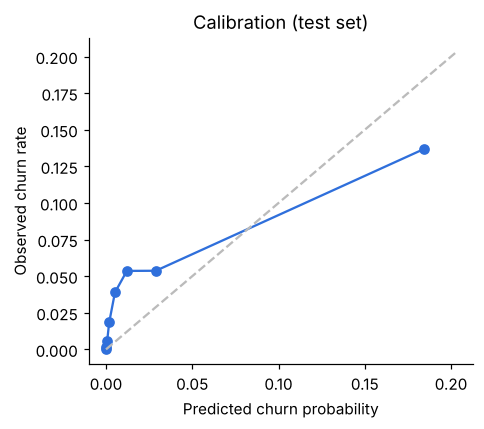

In [5]:
p = scores["Gradient boosting"]
frac, mean_pred = calibration_curve(y, p, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(mean_pred, frac, marker="o", color=BLUE)
lim = max(mean_pred.max(), frac.max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="#bbb")
ax.set(xlabel="Predicted churn probability", ylabel="Observed churn rate", title="Calibration (test set)")
plt.tight_layout()
print(f"Mean predicted {p.mean():.1%} vs observed {y.mean():.1%}")

The ranking is good but the probabilities run low: the model predicts about 3% churn where about 4%
happened. Churn was only slightly higher in the test months than in training, so drift explains little
of the gap. Before treating the scores as forecasts, recalibrate them (for example isotonic regression
on the most recent labelled months). Until then, the dashboard uses "expected MRR at risk" to rank and
compare accounts, not as a revenue forecast.

## What drives the predictions?

Permutation importance: how much the test PR AUC drops when one feature is shuffled. It measures what
the model *uses*, which isn't necessarily what *causes* churn.

,logistic coefficient (standardised)
months_to_renewal,-2.726049
sessions_28d,-1.882438
is_annual,1.703103
user_days_28d,-1.360933
users_total,1.237058
discount_pct,-1.047055
segment_Enterprise,-0.925240
segment_SMB,0.840647


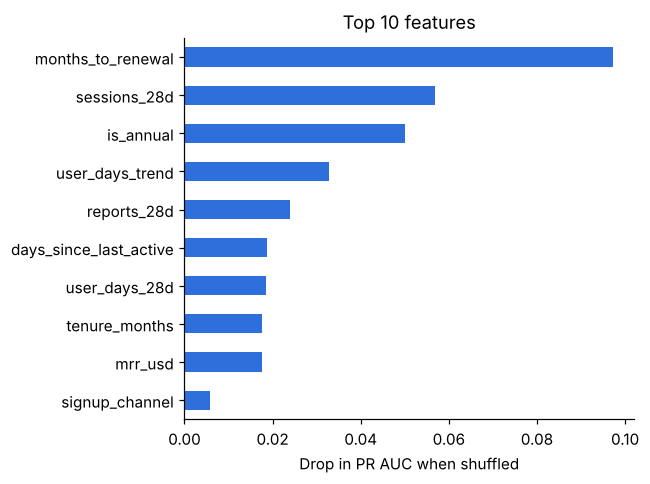

In [6]:
gb = models["Gradient boosting"]
imp = permutation_importance(gb, test[FEATURES], y, scoring="average_precision", n_repeats=10, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(6, 4.5))
importance.tail(10).plot.barh(ax=ax, color=BLUE)
ax.set(xlabel="Drop in PR AUC when shuffled", title="Top 10 features")
plt.tight_layout()

lr = models["Logistic regression"]
names = list(NUMERIC) + list(lr[0].named_transformers_["onehotencoder"].get_feature_names_out(CATEGORICAL))
coef = pd.Series(lr[-1].coef_[0], index=names)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).to_frame("logistic coefficient (standardised)")

The signals line up with how churn actually happens:

- **Time to renewal** matters most. Annual customers can only leave at renewal, so an annual account
  months away from renewal is safe this quarter whatever its usage.
- **Usage, and especially usage dropping off**: fewer sessions and reports, fewer active user-days than
  the month before, more days since anyone logged in. Disengagement shows up weeks before the
  cancellation.
- **Segment adds little once usage is known.** SMB accounts churn more mostly *because* they use the
  product less, which the usage features already capture.

## Score today's customers

Refit on every labelled snapshot, score each account paying on 1 October 2026, and write the result to
the warehouse as `ml.churn_risk_scores` so the dashboard can show the at-risk list and the MRR behind it.

In [7]:
final = models["Gradient boosting"].fit(data[FEATURES], data[LABEL])
today = snapshot(inputs, pd.Timestamp("2026-10-01"))
today["churn_probability"] = final.predict_proba(today[FEATURES])[:, 1]
cutoff_high = today["churn_probability"].quantile(0.9)
cutoff_med = today["churn_probability"].quantile(0.7)
today["risk_tier"] = np.select([today["churn_probability"] >= cutoff_high, today["churn_probability"] >= cutoff_med],
                               ["High", "Medium"], "Low")
today["expected_mrr_at_risk_usd"] = today["churn_probability"] * today["mrr_usd"]

scores_table = today[["account_id", "snapshot_date", "segment", "mrr_usd", "churn_probability", "risk_tier",
                      "expected_mrr_at_risk_usd", "user_days_trend", "days_since_last_active",
                      "months_to_renewal"]].rename(columns={"snapshot_date": "scored_at"})
write(scores_table, "ml.churn_risk_scores")

print(f"Scored {len(scores_table):,} paying accounts. Expected MRR at risk in the next 60 days: "
      f"${scores_table['expected_mrr_at_risk_usd'].sum():,.0f} of ${scores_table['mrr_usd'].sum():,.0f}")
scores_table.groupby("risk_tier").agg(accounts=("account_id", "size"), mrr_usd=("mrr_usd", "sum"),
                                      expected_mrr_at_risk_usd=("expected_mrr_at_risk_usd", "sum")).round(0)

Scored 847 paying accounts. Expected MRR at risk in the next 60 days: $3,077 of $223,252


,accounts,mrr_usd,expected_mrr_at_risk_usd
risk_tier,,,
High,85,11955.0,1823.0
Low,593,192101.0,459.0
Medium,169,19196.0,795.0


## Summary and limitations

- **Useful, not magic.** Contacting the 10% of accounts the model rates riskiest each month reaches
  about four times as many churners as contacting accounts at random, and roughly 40% of all churners.
- **Simple wins on cost.** Logistic regression is within a hair of gradient boosting, so it's the
  natural fallback if explainability or monitoring matter more than the last point of AUC.
- **Overlapping labels.** Monthly snapshots with a 60-day horizon mean a single cancellation can be the
  positive label in two consecutive snapshots. That doesn't leak information across the time split,
  but it does make the test metrics slightly optimistic in count terms.
- **Correlation, not cause.** The model flags accounts whose usage is fading; it doesn't say why, or what
  would save them. Measuring that needs a holdout: leave some flagged accounts uncontacted and compare.
- **Next steps.** Score monthly in the pipeline (an Airflow task after dbt) and track precision of the
  High tier as outcomes arrive, to catch drift.